# Raw data extraction and overview

Set the project root so this notebook works whether Jupyter starts in the repository root or `notebooks/`. Import the shared paths and seed from `src/config.py`, then load the untouched raw CSV.

In [1]:
import os
import json
import random
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise FileNotFoundError("Could not locate src/config.py from the current directory")
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import ARTIFACTS, RAW_PATH, SEED

random.seed(SEED)
np.random.seed(SEED)

df = pd.read_csv(RAW_PATH)
print("Loaded raw dataset from:", RAW_PATH)

Loaded raw dataset from: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/data/raw/creditcard.csv


## Dataset size, sample, types, and memory

Inspect the row and column count, first rows, inferred data types, and memory use without changing the data.

In [2]:
print("Shape:", df.shape)
display(df.head())
print("Data types:")
display(df.dtypes.rename("dtype").to_frame())
memory_usage = df.memory_usage(deep=True)
print("Memory usage by column (bytes):")
display(memory_usage.rename("bytes").to_frame())
print("Total memory usage (MiB): {:.2f}".format(memory_usage.sum() / (1024 ** 2)))

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Data types:


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


Memory usage by column (bytes):


,bytes
Index,128
Time,2278456
V1,2278456
V2,2278456
V3,2278456
V4,2278456
V5,2278456
V6,2278456
V7,2278456
V8,2278456


Total memory usage (MiB): 67.36


## Required schema check

Confirm that `Time`, `V1` through `V28`, `Amount`, and `Class` are present and numeric. This is an inspection only; no columns are changed.

In [3]:
required_columns = ["Time"] + ["V{}".format(i) for i in range(1, 29)] + ["Amount", "Class"]
missing_columns = [column for column in required_columns if column not in df.columns]
non_numeric_columns = [
    column for column in required_columns
    if column in df.columns and not pd.api.types.is_numeric_dtype(df[column])
]
schema_check = pd.DataFrame(
    {
        "check": ["Required columns present", "Required columns numeric"],
        "passed": [not missing_columns, not non_numeric_columns],
        "details": [
            "All required columns are present" if not missing_columns else "Missing: {}".format(missing_columns),
            "All required columns are numeric" if not non_numeric_columns else "Non-numeric: {}".format(non_numeric_columns),
        ],
    }
)
display(schema_check)
print("Required columns ({}): {}".format(len(required_columns), required_columns))

,check,passed,details
0,Required columns present,True,All required columns are present
1,Required columns numeric,True,All required columns are numeric


Required columns (31): ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


## Descriptive statistics

Show the descriptive statistics for the transaction time, amount, and class label.

In [4]:
display(df[["Time", "Amount", "Class"]].describe())

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


## Class balance

Report class counts and the fraud percentage, then plot the observed count of each class.

Class counts:


,count
Class,
0,284315
1,492


Fraud percentage: 0.1727%


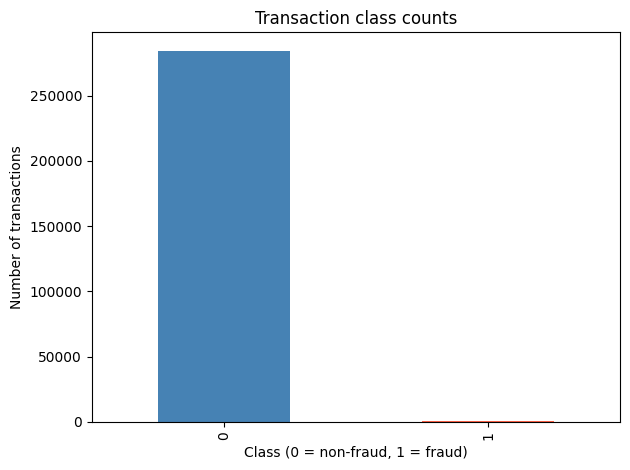

In [5]:
class_counts = df["Class"].value_counts().sort_index()
fraud_count = int(class_counts.get(1, 0))
fraud_rate = float(fraud_count / len(df))
fraud_percentage = fraud_rate * 100
print("Class counts:")
display(class_counts.rename("count").to_frame())
print("Fraud percentage: {:.4f}%".format(fraud_percentage))

ax = class_counts.plot(kind="bar", color=["steelblue", "tomato"], title="Transaction class counts")
ax.set_xlabel("Class (0 = non-fraud, 1 = fraud)")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

## Time range and amount distribution

Show the observed time range in seconds and hours. Plot amount with its original values in a standard histogram and with a logarithmic count axis; the latter changes only the plot scale, not the data.

Time range: 0 to 172792 seconds
Time range: 0.0000 to 47.9978 hours


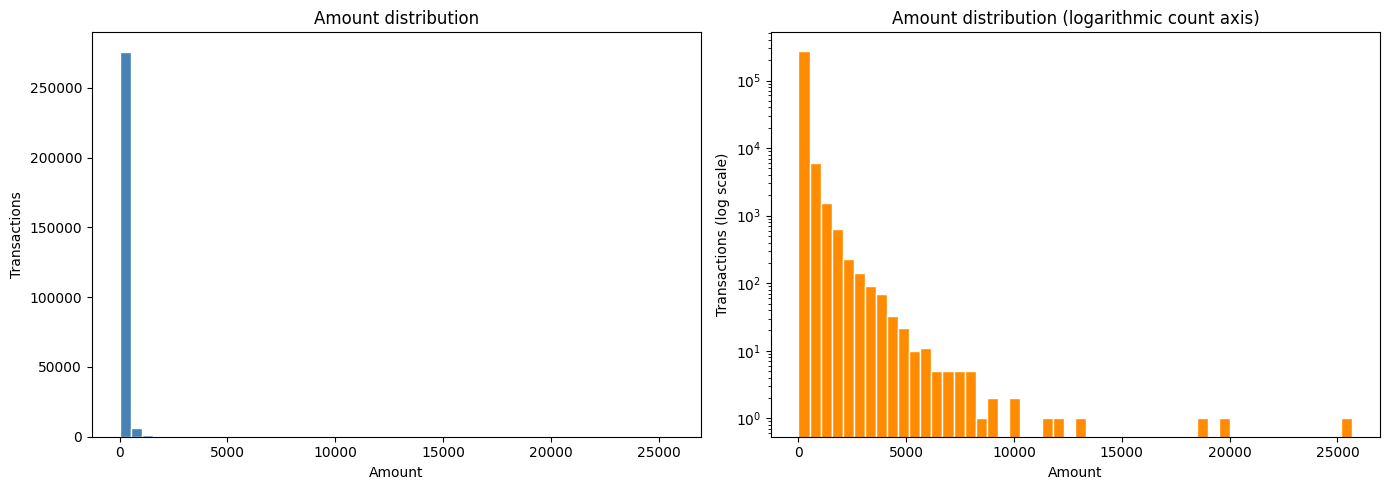

In [6]:
time_min_seconds = float(df["Time"].min())
time_max_seconds = float(df["Time"].max())
print("Time range: {:.0f} to {:.0f} seconds".format(time_min_seconds, time_max_seconds))
print("Time range: {:.4f} to {:.4f} hours".format(time_min_seconds / 3600, time_max_seconds / 3600))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["Amount"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Amount distribution")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Transactions")
axes[1].hist(df["Amount"], bins=50, color="darkorange", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("Amount distribution (logarithmic count axis)")
axes[1].set_xlabel("Amount")
axes[1].set_ylabel("Transactions (log scale)")
plt.tight_layout()
plt.show()

## Missing values, duplicates, and extraction report

Count missing values and exact duplicate rows without removing either. Save the requested summary as JSON under the configured artifacts directory.

In [7]:
missing_by_column = df.isna().sum().astype(int)
duplicate_count = int(df.duplicated().sum())
print("Missing values by column:")
display(missing_by_column.rename("missing_values").to_frame())
print("Total missing values:", int(missing_by_column.sum()))
print("Exact duplicate rows:", duplicate_count)

extraction_report = {
    "shape": [int(df.shape[0]), int(df.shape[1])],
    "fraud_count": fraud_count,
    "fraud_rate": fraud_rate,
    "fraud_percentage": fraud_percentage,
    "missing": {column: int(count) for column, count in missing_by_column.items()},
    "duplicates": duplicate_count,
    "time_range": {
        "seconds": {"min": time_min_seconds, "max": time_max_seconds},
        "hours": {"min": time_min_seconds / 3600, "max": time_max_seconds / 3600},
    },
}
extraction_report_path = Path(ARTIFACTS) / "extraction_report.json"
extraction_report_path.write_text(
    json.dumps(extraction_report, indent=2) + "\n",
    encoding="utf-8",
)
print("Saved extraction report to:", extraction_report_path)

Missing values by column:


,missing_values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing values: 0
Exact duplicate rows: 1081
Saved extraction report to: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/artifacts/extraction_report.json


## Key findings

The raw dataset contains **284,807 transactions** and **31 numeric columns**, including all required fields. There are **492 fraud transactions** (about **0.1727%**), so the class distribution is highly imbalanced. The CSV has **no missing values** and **1,081 exact duplicate rows**; neither is removed in this extraction notebook. Transaction times span **0 to 172,792 seconds** (about **0 to 47.9978 hours**). Amounts have a right-skewed distribution, with a logarithmic count-axis view included to make lower-frequency bins visible. The full summary is saved to `artifacts/extraction_report.json`.